# Figure S1 — short test

Separate terrain-control policies, unit-state and activity-scaled sensitivity, and natural-response histories.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'terrain-sensitivity'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: terrain-sensitivity | cuda:0 | runs/notebooks/terrain-sensitivity


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 24.7 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 285.6 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 177.1 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 8.4 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 6.7 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 14.3 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,terrain-sensitivity,"connectome, mlp",[2011]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,24.66
1,train,True,285.58
2,evaluate,True,177.10
3,probe,True,8.39
4,analyze,True,6.67
5,plot,True,14.35


`analysis/seed_sensitivity.csv` (first eight rows)

,training_seed,pulse_time_s,horizon_ms,scale,category,energy,rms,full_share,afferent_enrichment
0,2011,0.12,10,activity_scaled,AN,6.381729e-05,0.000193,0.382392,8.309735
1,2011,0.12,10,activity_scaled,DN,7.890063e-05,0.000247,0.472772,NaN
2,2011,0.12,10,activity_scaled,DNg35,1.118067e-06,0.000748,0.006699,NaN
3,2011,0.12,10,activity_scaled,DNg78,1.010127e-07,0.000225,0.000605,NaN
4,2011,0.12,10,activity_scaled,DNge037,9.989901e-06,0.002235,0.059859,NaN
5,2011,0.12,10,activity_scaled,SA,2.002129e-05,0.000205,0.119967,9.378636
6,2011,0.12,10,activity_scaled,brain_motor,9.285717e-07,0.000094,0.005564,NaN
7,2011,0.12,10,activity_scaled,gustatory,2.810918e-08,0.000008,0.000168,0.015394


`figures/paper/Historical_obstacle_cue_exchange.png`

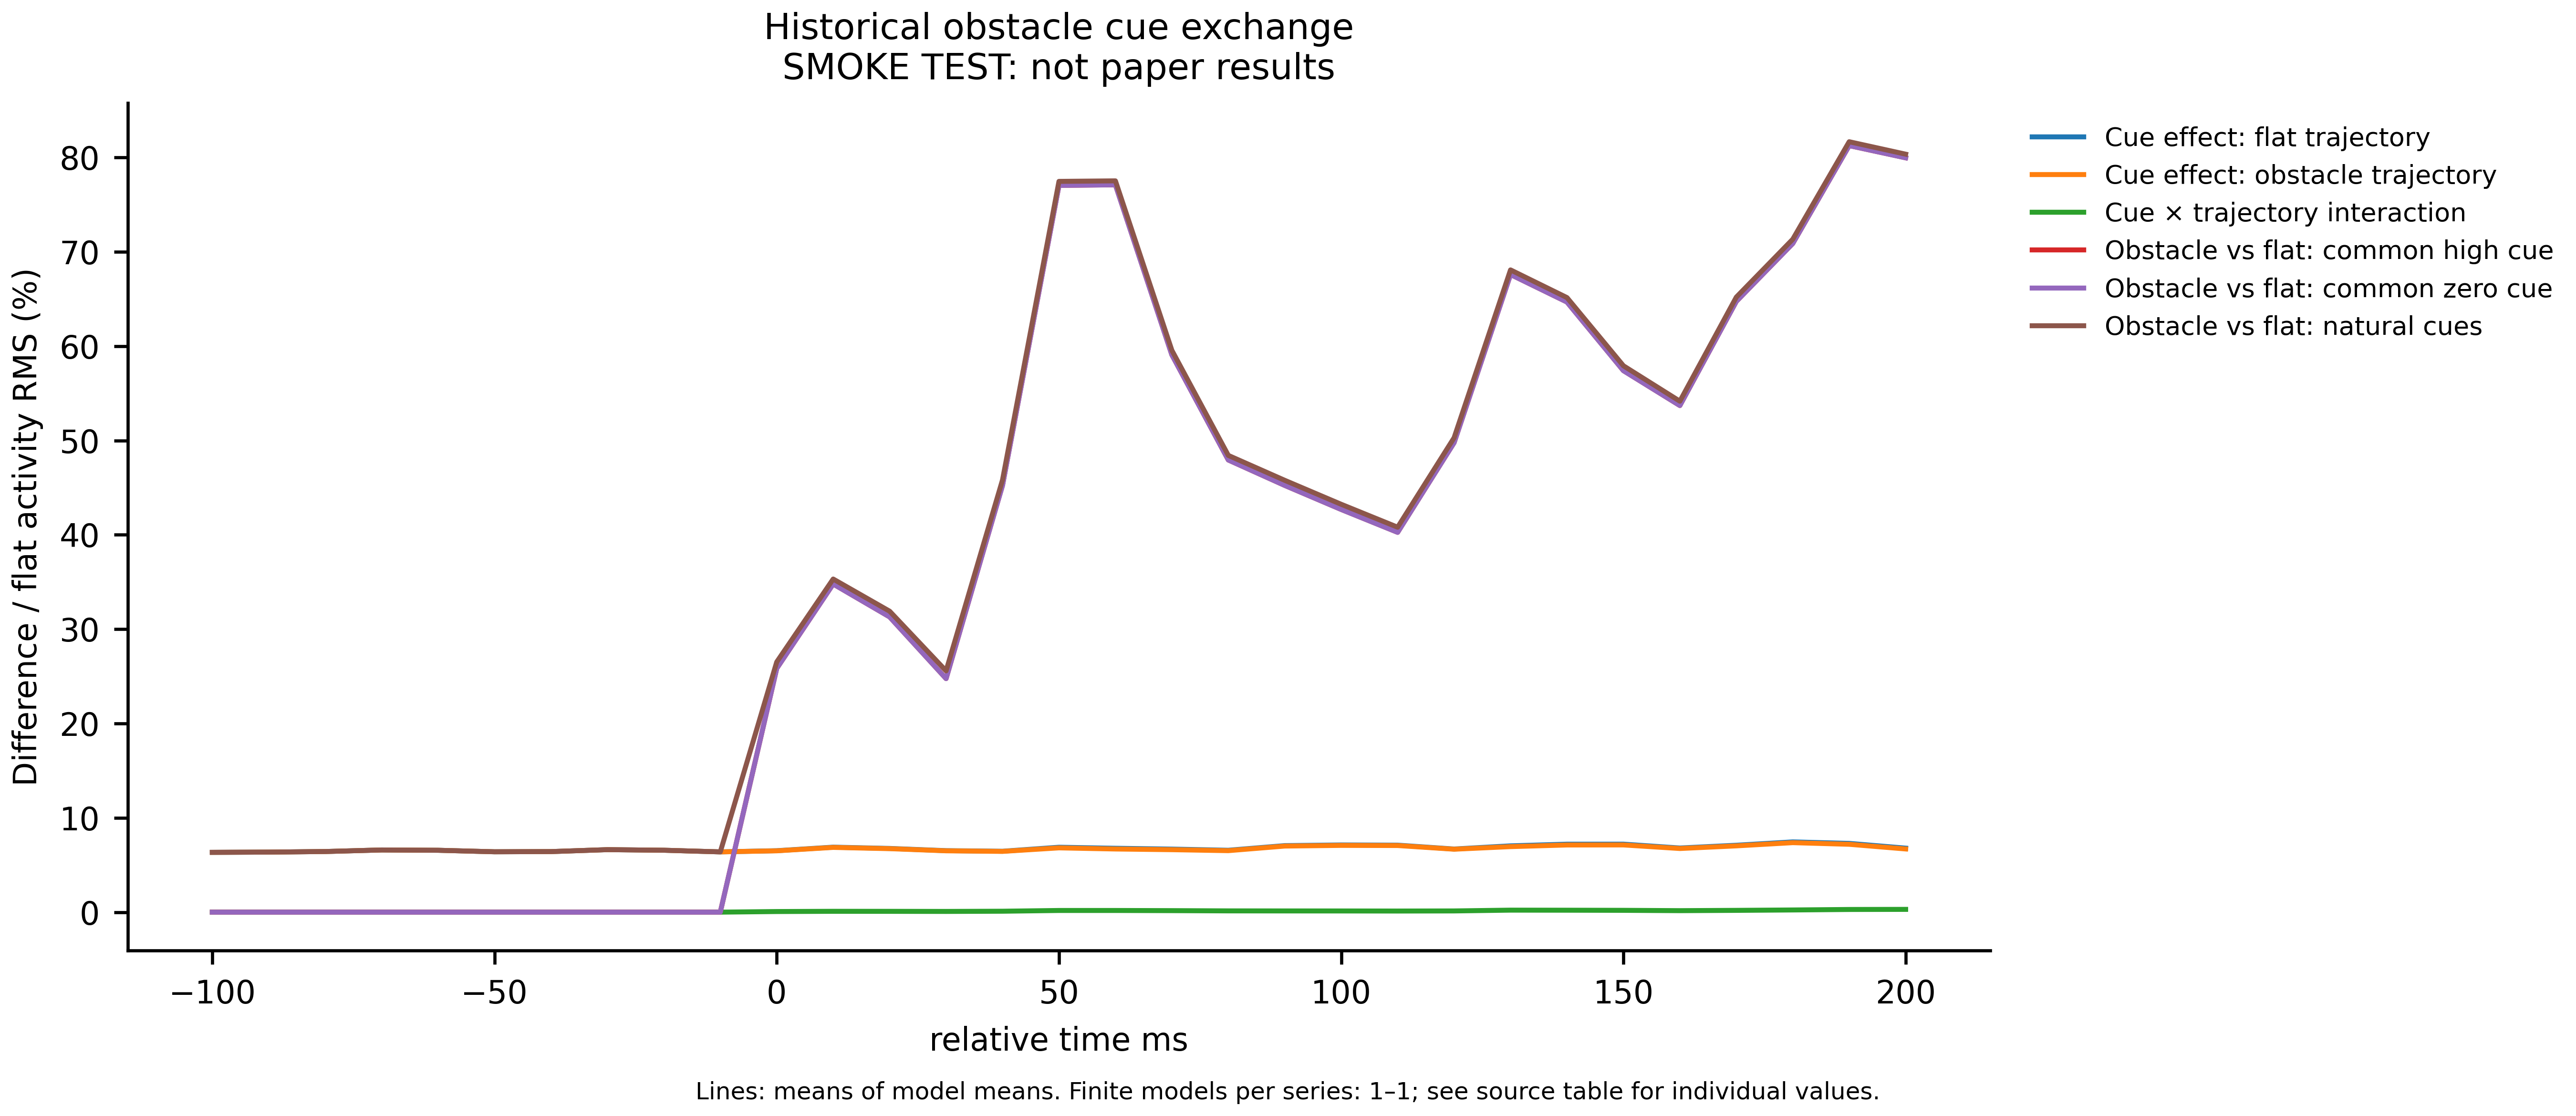

`figures/paper/S1_RMS_activity_scaled_pulse0_12.png`

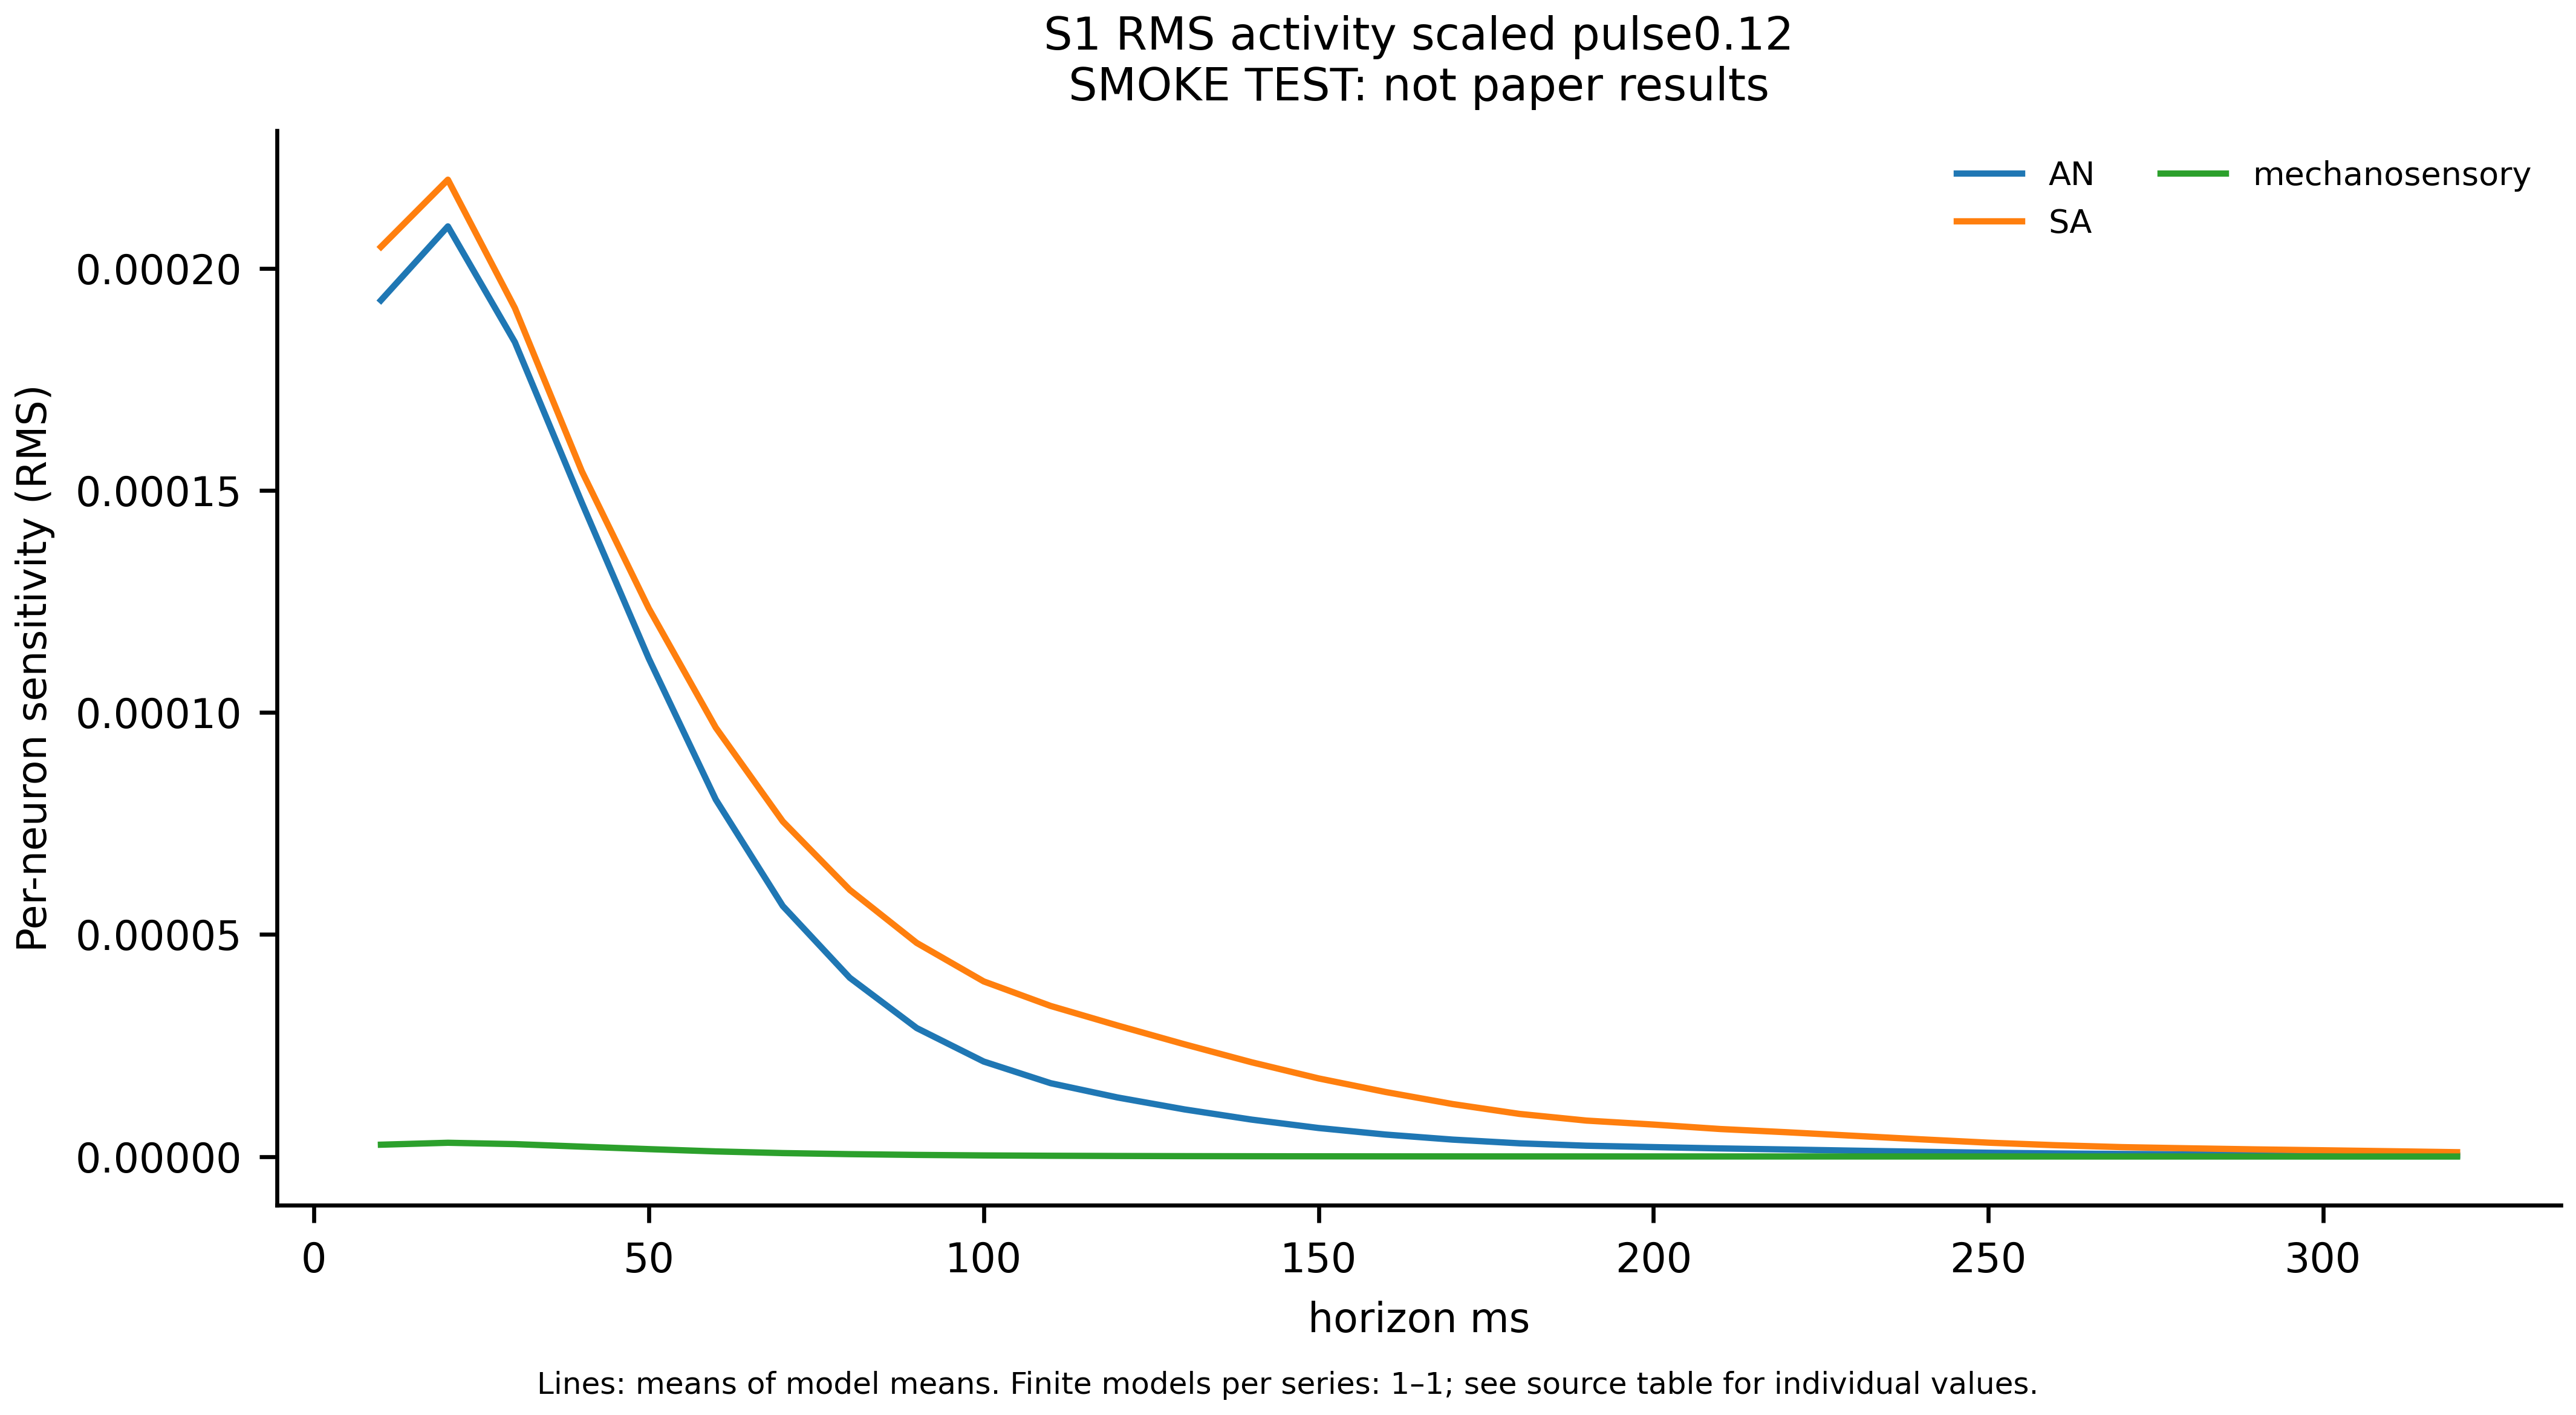

`figures/paper/S1_RMS_activity_scaled_pulse0_32.png`

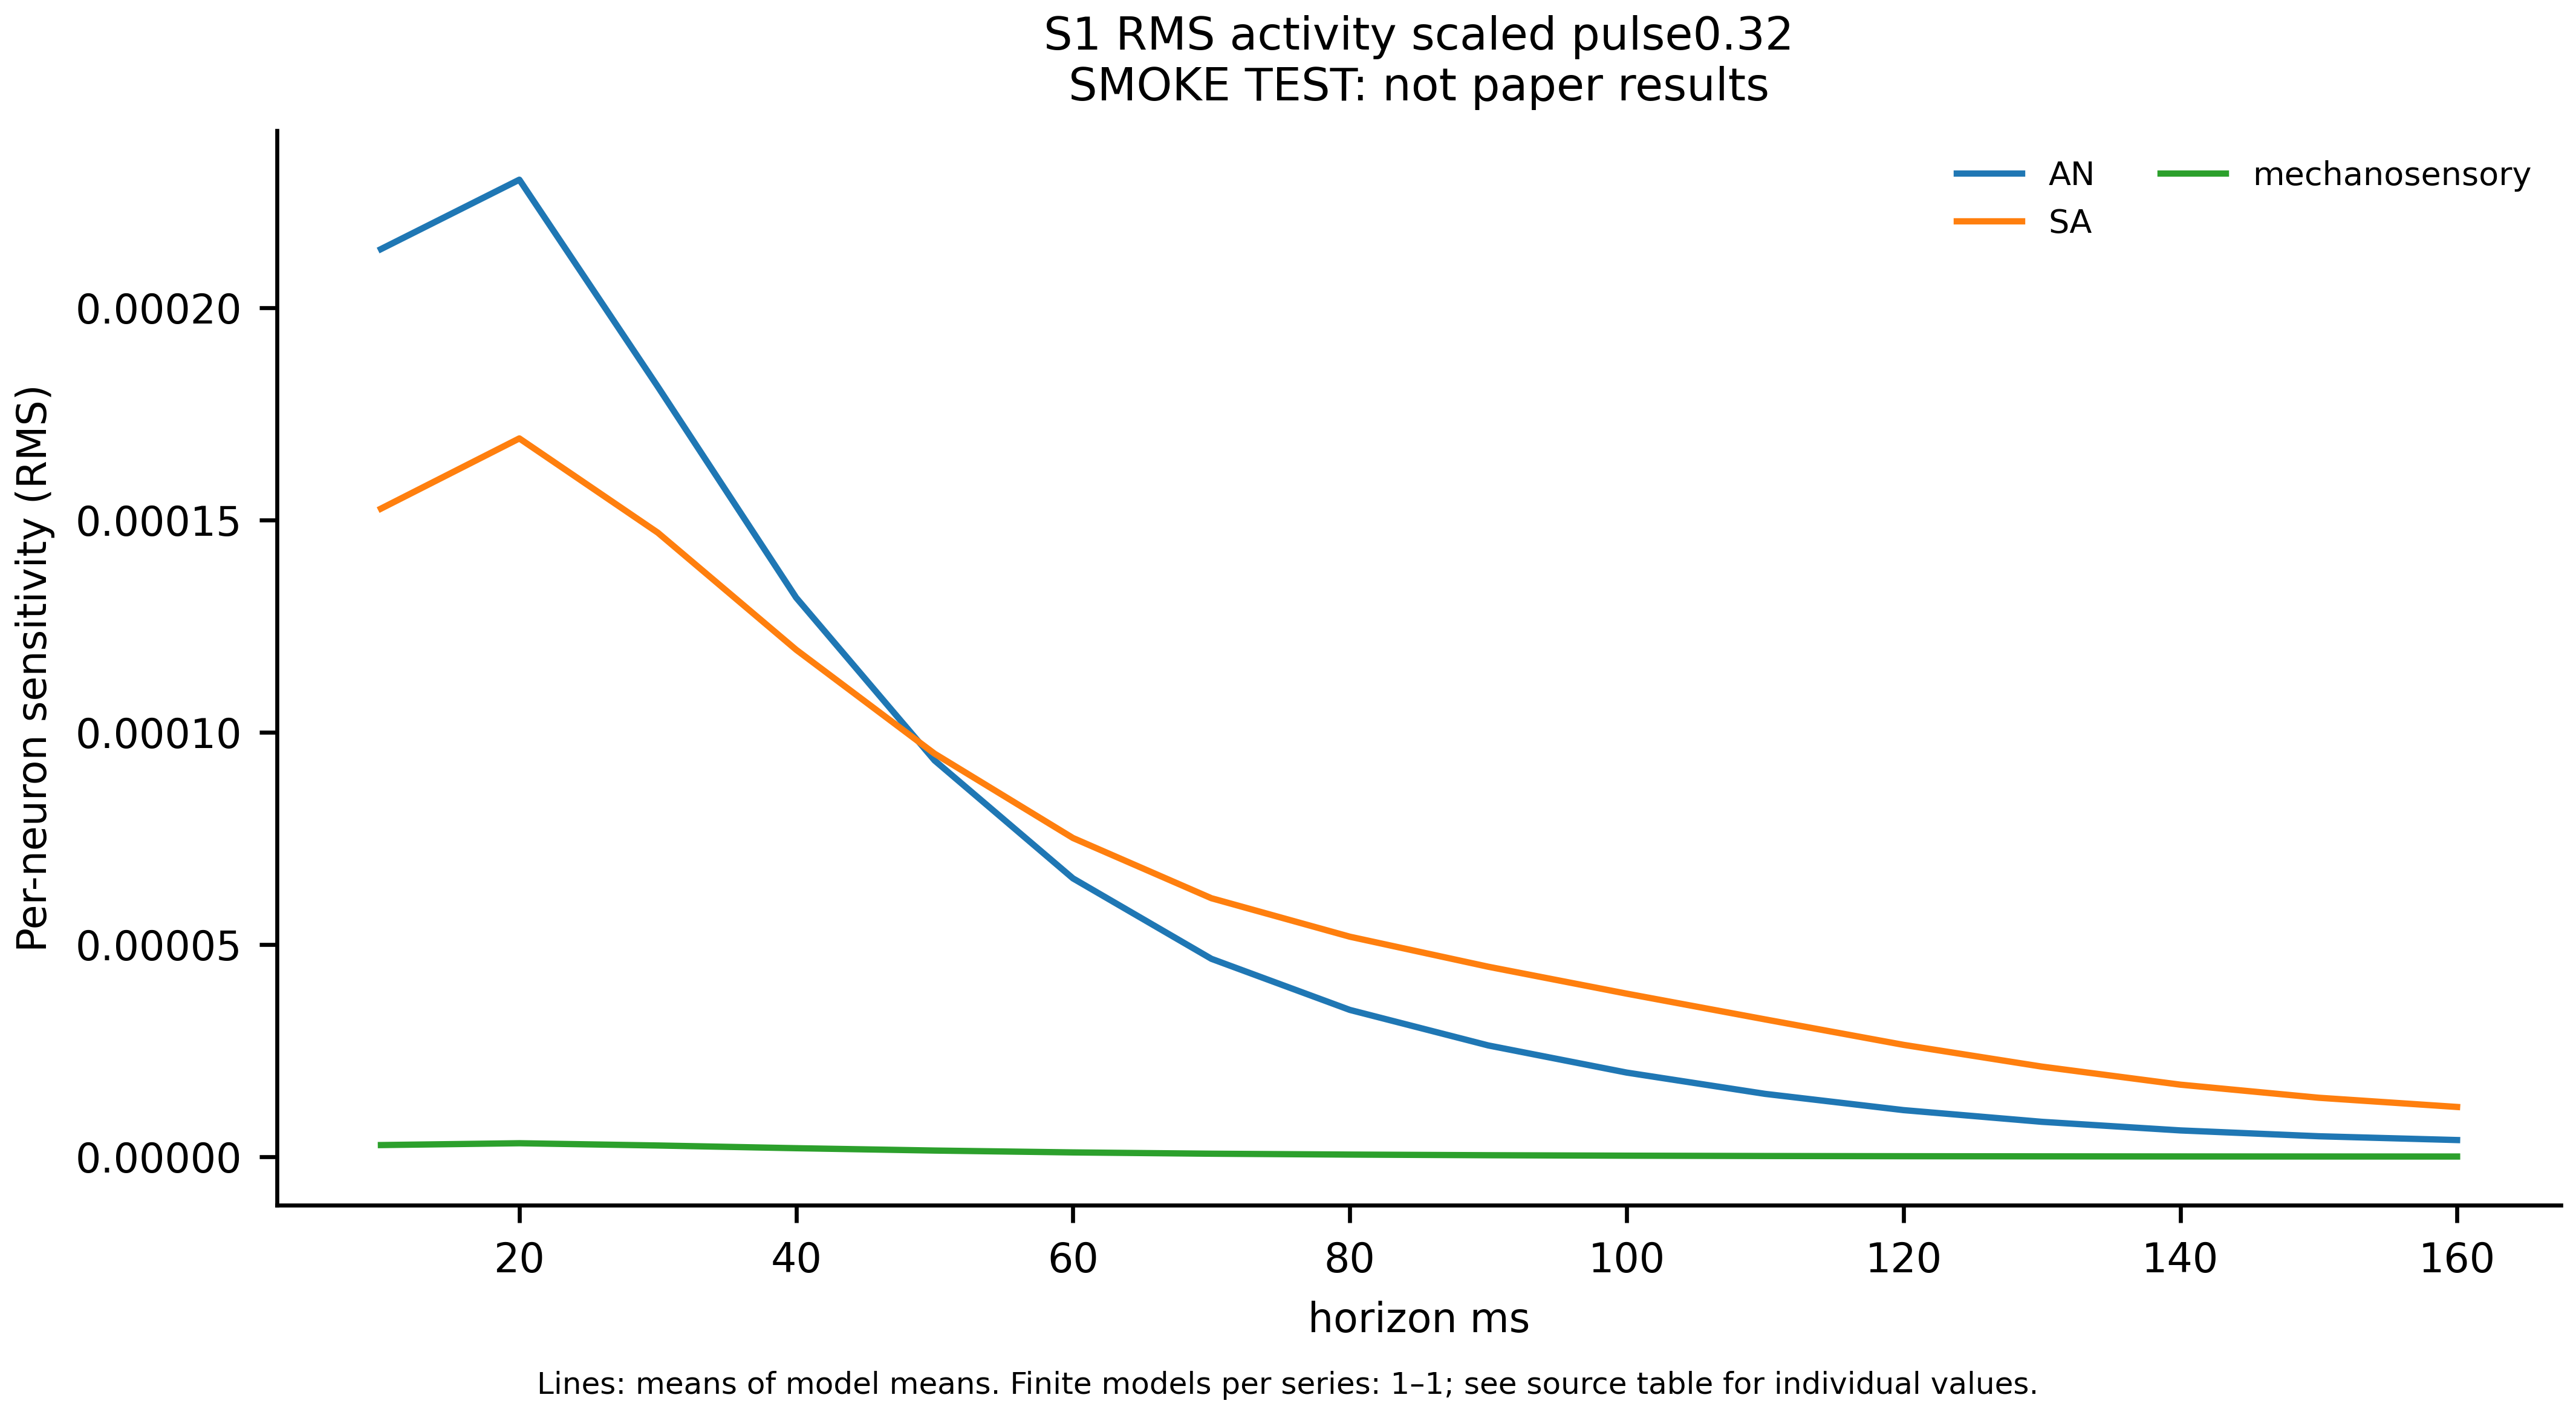

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/S01_terrain_sensitivity.py --run-dir runs/terrain-sensitivity --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config terrain-sensitivity --run-dir runs/terrain-sensitivity --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
